# State Preparation — Cluster States (Qiskit)
## 4-Qubit Linear Cluster State

**Chapter / concept:** State Preparation — Graph / Cluster States (Measurement-Based Quantum Computing building block)

**Circuit implemented:** 4-qubit linear-chain cluster state on graph `0 — 1 — 2 — 3`
(edges: (0,1), (1,2), (2,3))

### Global SETUP (must match the CUDA-Q notebook exactly)
- N_QUBITS = 4
- Gate sequence: `H` on every qubit (q0,q1,q2,q3), then `CZ(0,1)`, `CZ(1,2)`, `CZ(2,3)` (in that order)
- QUBIT ORDERING CONTRACT: qubit 0 = **rightmost** bit in every printed bitstring
  (Qiskit's native convention — **no reversal needed in this notebook**)
- SHOTS = 10000, SEED = 42
- GLOBAL PHASE CONVENTION: the first amplitude with `abs(amp) > 1e-9`, in ascending
  bitstring order, is rotated (multiplied by `exp(-1j*phase)`) to be real and positive
- Basis ordering for all matrices: `{|00..0>, |00..1>, ..., |11..1>}` ascending binary order

### Theory recap
A cluster (graph) state on graph $G=(V,E)$ is prepared as:
$$|\psi_G\rangle = \prod_{(i,j)\in E} CZ_{i,j} \; H^{\otimes n} |0\rangle^{\otimes n}$$
For our linear graph $0-1-2-3$, every computational basis amplitude has magnitude $1/4$
(since it's a stabilizer state built from Clifford gates on $|+\rangle^{\otimes 4}$), and
the sign of basis state $|q_3q_2q_1q_0\rangle$ is
$$(-1)^{\,q_0 q_1 \,+\, q_1 q_2 \,+\, q_2 q_3}$$
so the measurement distribution is **exactly uniform**: every one of the 16 outcomes has
probability $1/16 = 0.0625$.

⚠️ **Ordering-convention warning:** this Qiskit notebook needs no bit reversal. The matched
CUDA-Q notebook indexes qubit 0 as the **leftmost/most-significant** bit and must explicitly
reverse every bitstring — see that notebook's dedicated ordering-fix cell.

**Run all cells top to bottom.**

In [1]:
# Install cell
# Exact package names: "qiskit" (core) + "qiskit-aer" (the Aer simulator backend) + "pylatexenc" (needed for circuit.draw(output="mpl") gate labels)
# Platform caveat: qiskit-aer wheels are provided for Linux/macOS/Windows x86_64; on other
# platforms (e.g. some ARM setups) you may need to build from source.
%pip install -q qiskit qiskit-aer pylatexenc

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 6.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 53.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 116.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 105.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 5.5 MB/s eta 0:00:00


In [2]:
# Imports + constants
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram

TOPIC_SLUG = "cluster_state_4q_linear"
N_QUBITS = 4
SHOTS = 10000
SEED = 42
EDGES = [(0, 1), (1, 2), (2, 3)]   # linear cluster-state graph

print("N_QUBITS:", N_QUBITS)
print("SHOTS:", SHOTS)
print("SEED:", SEED)
print("EDGES:", EDGES)

N_QUBITS: 4
SHOTS: 10000
SEED: 42
EDGES: [(0, 1), (1, 2), (2, 3)]


In [3]:
# Build the circuit gate-by-gate
qc = QuantumCircuit(N_QUBITS, name="cluster_state_4q_linear")

# Step 1: put every qubit into |+> = H|0>, the standard cluster-state starting layer
qc.h(0)  # qubit 0 -> equal superposition |0>+|1>
qc.h(1)  # qubit 1 -> equal superposition |0>+|1>
qc.h(2)  # qubit 2 -> equal superposition |0>+|1>
qc.h(3)  # qubit 3 -> equal superposition |0>+|1>

# Step 2: entangle neighboring qubits along the graph edges with controlled-Z.
# CZ(i,j) flips the sign of the amplitude wherever BOTH qubit i and qubit j are |1>.
qc.cz(0, 1)  # edge (0,1)
qc.cz(1, 2)  # edge (1,2)
qc.cz(2, 3)  # edge (2,3)

print(qc)

     ┌───┐         
q_0: ┤ H ├─■───────
     ├───┤ │       
q_1: ┤ H ├─■──■────
     ├───┤    │    
q_2: ┤ H ├────■──■─
     ├───┤       │ 
q_3: ┤ H ├───────■─
     └───┘         


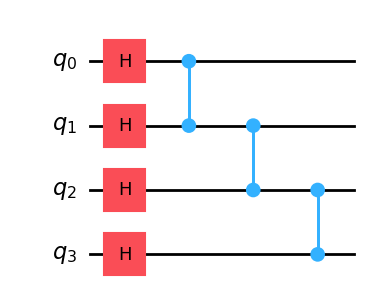

In [4]:
# Draw the circuit with matplotlib and save it
fig = qc.draw(output="mpl")
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", bbox_inches="tight")
fig

In [5]:
# Explicit matrix representation, cross-checked two ways, basis = ascending binary {|0000>,...,|1111>}
H_gate = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)
I2 = np.eye(2, dtype=complex)

def kron_n(ops):
    out = ops[0]
    for o in ops[1:]:
        out = np.kron(out, o)
    return out

# (a) built by hand in NumPy: H on every qubit (order-independent since it's H on all qubits),
# combined with the graph's CZ diagonal matrices, using index bit k = qubit k (qubit0 = LSB)
H_full = kron_n([H_gate] * N_QUBITS)

def cz_matrix(i, j, n):
    dim = 2 ** n
    M = np.eye(dim, dtype=complex)
    for idx in range(dim):
        bi = (idx >> i) & 1
        bj = (idx >> j) & 1
        if bi == 1 and bj == 1:
            M[idx, idx] = -1
    return M

U_hand = H_full.copy()
for (i, j) in EDGES:
    U_hand = cz_matrix(i, j, N_QUBITS) @ U_hand

print("Hand-built combined unitary (rounded, first 4x4 block):")
print(np.round(U_hand[:4, :4], 4))

# (b) from Qiskit's own operator extraction
U_qiskit = Operator(qc).data

print("\nQiskit Operator() combined unitary (rounded, first 4x4 block):")
print(np.round(U_qiskit[:4, :4], 4))

match = np.allclose(U_hand, U_qiskit, atol=1e-8)
print("\nHand-built matrix matches Qiskit Operator():", match)
assert match, "Matrix cross-check failed!"


Hand-built combined unitary (rounded, first 4x4 block):
[[ 0.25+0.j  0.25+0.j  0.25+0.j  0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j -0.25+0.j]
 [ 0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j]
 [-0.25+0.j  0.25+0.j  0.25+0.j -0.25+0.j]]

Qiskit Operator() combined unitary (rounded, first 4x4 block):
[[ 0.25+0.j  0.25+0.j  0.25+0.j  0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j -0.25+0.j]
 [ 0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j]
 [-0.25+0.j  0.25+0.j  0.25+0.j -0.25+0.j]]

Hand-built matrix matches Qiskit Operator(): True


In [6]:
# Exact statevector: extract, apply global-phase normalization (no bit-order fix needed here), print
sv = Statevector.from_instruction(qc)
amps = sv.data.copy()

def normalize_global_phase(amps, n_qubits):
    """Find first amplitude with abs(amp) > 1e-9 in ascending bitstring order,
    rotate the whole vector so that amplitude becomes real and positive."""
    amps = amps.copy()
    for idx in range(len(amps)):
        if abs(amps[idx]) > 1e-9:
            phase = np.angle(amps[idx])
            amps = amps * np.exp(-1j * phase)
            break
    return amps

amps = normalize_global_phase(amps, N_QUBITS)

prob_dict = {}
print("Statevector amplitudes (qubit 0 = rightmost bit):")
for idx in range(2 ** N_QUBITS):
    bitstring = format(idx, f"0{N_QUBITS}b")   # Qiskit's own bitstring already has qubit0 rightmost
    amp = amps[idx]
    prob_dict[bitstring] = float(abs(amp) ** 2)
    if abs(amp) > 1e-9:
        print(f"  |{bitstring}>: {amp.real:+.4f}{amp.imag:+.4f}j")

prob_dict = dict(sorted(prob_dict.items()))
print("\nProbability dictionary (sorted by bitstring):")
print(prob_dict)

Statevector amplitudes (qubit 0 = rightmost bit):
  |0000>: +0.2500+0.0000j
  |0001>: +0.2500+0.0000j
  |0010>: +0.2500+0.0000j
  |0011>: -0.2500+0.0000j
  |0100>: +0.2500+0.0000j
  |0101>: +0.2500+0.0000j
  |0110>: -0.2500+0.0000j
  |0111>: +0.2500+0.0000j
  |1000>: +0.2500+0.0000j
  |1001>: +0.2500+0.0000j
  |1010>: +0.2500+0.0000j
  |1011>: -0.2500+0.0000j
  |1100>: -0.2500+0.0000j
  |1101>: -0.2500+0.0000j
  |1110>: +0.2500+0.0000j
  |1111>: -0.2500+0.0000j

Probability dictionary (sorted by bitstring):
{'0000': 0.06249999999999996, '0001': 0.06249999999999996, '0010': 0.06249999999999996, '0011': 0.06249999999999996, '0100': 0.06249999999999996, '0101': 0.06249999999999996, '0110': 0.06249999999999996, '0111': 0.06249999999999996, '1000': 0.06249999999999996, '1001': 0.06249999999999996, '1010': 0.06249999999999996, '1011': 0.06249999999999996, '1100': 0.06249999999999996, '1101': 0.06249999999999996, '1110': 0.06249999999999996, '1111': 0.06249999999999996}


### Ordering-fix note (Qiskit)
**No bit reversal was applied.** Qiskit already returns statevector amplitudes and measurement
bitstrings with qubit 0 as the rightmost (least-significant) character, which is exactly the
QUBIT ORDERING CONTRACT declared in the setup above. This is the reference convention that the
CUDA-Q notebook's amplitudes/counts are reversed *to* match.

In [7]:
# Measurement cell: shared SEED / SHOTS
qc_meas = qc.copy()
qc_meas.measure_all()

sim = AerSimulator(seed_simulator=SEED)
tqc = transpile(qc_meas, sim, seed_transpiler=SEED)
job = sim.run(tqc, shots=SHOTS, seed_simulator=SEED)
result = job.result()
counts = result.get_counts()

# convert to probabilities (Qiskit counts keys already have qubit0 rightmost, no reorder needed)
total = sum(counts.values())
measured_probs = {k: v / total for k, v in sorted(counts.items())}

print("Raw counts:", dict(sorted(counts.items())))
print("\nMeasured probabilities:", measured_probs)

Raw counts: {'0000': 589, '0001': 662, '0010': 633, '0011': 625, '0100': 632, '0101': 618, '0110': 692, '0111': 638, '1000': 593, '1001': 575, '1010': 625, '1011': 644, '1100': 621, '1101': 617, '1110': 592, '1111': 644}

Measured probabilities: {'0000': 0.0589, '0001': 0.0662, '0010': 0.0633, '0011': 0.0625, '0100': 0.0632, '0101': 0.0618, '0110': 0.0692, '0111': 0.0638, '1000': 0.0593, '1001': 0.0575, '1010': 0.0625, '1011': 0.0644, '1100': 0.0621, '1101': 0.0617, '1110': 0.0592, '1111': 0.0644}


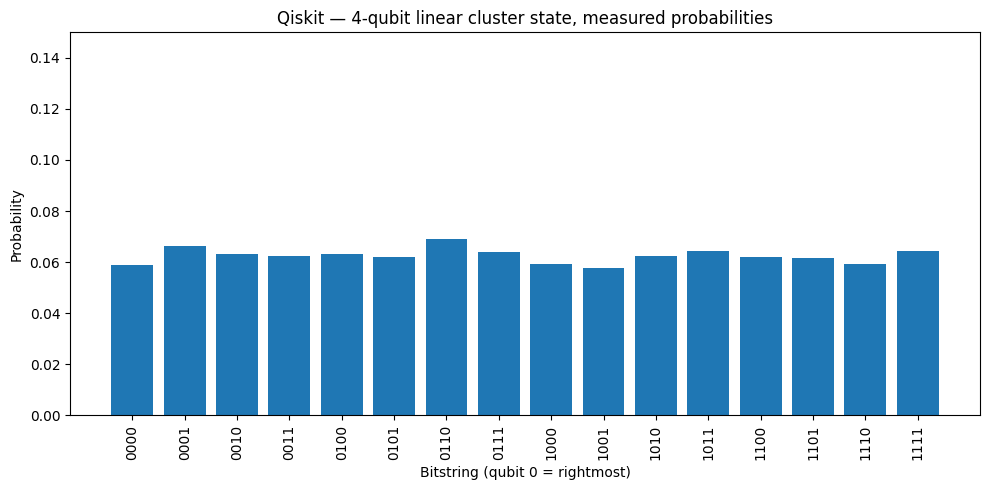

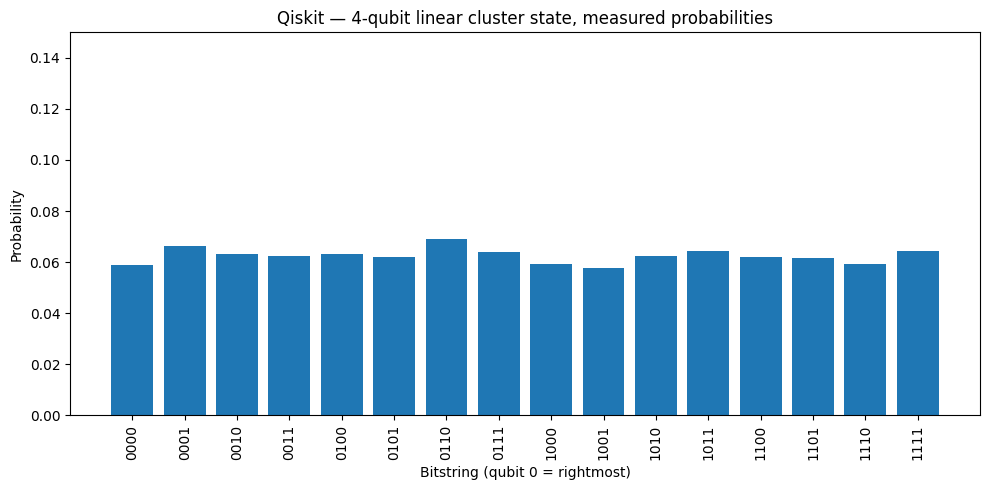

In [8]:
# Histogram cell
fig2, ax = plt.subplots(figsize=(10, 5))
labels = [format(i, f"0{N_QUBITS}b") for i in range(2 ** N_QUBITS)]
heights = [measured_probs.get(l, 0.0) for l in labels]
ax.bar(labels, heights, color="#1f77b4")
ax.set_xlabel("Bitstring (qubit 0 = rightmost)")
ax.set_ylabel("Probability")
ax.set_title("Qiskit — 4-qubit linear cluster state, measured probabilities")
ax.set_ylim(0, 0.15)
plt.xticks(rotation=90)
plt.tight_layout()
fig2.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", bbox_inches="tight")
fig2

In [9]:
# Resource counts
print("Circuit depth:", qc.depth())
print("Gate counts:", dict(qc.count_ops()))

Circuit depth: 4
Gate counts: {'h': 4, 'cz': 3}


### Convention notes (plain text)
- **Bit ordering:** qubit 0 = rightmost printed bit everywhere in this notebook. This is
  Qiskit's native convention, so no reversal was applied at any stage (statevector or counts).
- **Global phase:** the statevector was rotated so the first amplitude with `abs(amp) > 1e-9`,
  taken in ascending bitstring order, is real and positive, before printing/comparing.

In [10]:
# Final result dict
QISKIT_RESULT = dict(sorted(prob_dict.items()))
print("QISKIT_RESULT =", QISKIT_RESULT)

QISKIT_RESULT = {'0000': 0.06249999999999996, '0001': 0.06249999999999996, '0010': 0.06249999999999996, '0011': 0.06249999999999996, '0100': 0.06249999999999996, '0101': 0.06249999999999996, '0110': 0.06249999999999996, '0111': 0.06249999999999996, '1000': 0.06249999999999996, '1001': 0.06249999999999996, '1010': 0.06249999999999996, '1011': 0.06249999999999996, '1100': 0.06249999999999996, '1101': 0.06249999999999996, '1110': 0.06249999999999996, '1111': 0.06249999999999996}


In [11]:
# Diff-check block (hand-computed expected result + comparison against CUDAQ_RESULT if available)
# Hand-computed expectation: this is a stabilizer cluster state -> EVERY one of the 16
# outcomes has probability exactly 1/16 = 0.0625.
expected = {format(i, f"0{N_QUBITS}b"): 1 / 16 for i in range(2 ** N_QUBITS)}
max_delta_vs_hand = max(abs(QISKIT_RESULT[k] - expected[k]) for k in expected)
print("Max |QISKIT_RESULT - hand-computed 1/16| :", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-1, "Statistical sampling deviation unexpectedly large!"  # loose bound: this compares SAMPLED probs (10000 shots) to exact 1/16

# Uncomment after running the CUDA-Q notebook and pasting its CUDAQ_RESULT dict here:
# CUDAQ_RESULT = { ... }
# max_delta = max(abs(QISKIT_RESULT[k] - CUDAQ_RESULT[k]) for k in QISKIT_RESULT)
# print("Max probability delta Qiskit vs CUDA-Q:", max_delta)
# assert max_delta < 1e-1, "Qiskit and CUDA-Q results disagree beyond sampling noise!"
# (Note: with SHOTS=10000 and true probability 1/16 each, expect small Poisson-type
#  fluctuations, not exact equality across sampled counts; the exact-statevector probability
#  dictionaries, if compared instead of the SAMPLED ones, should match to numerical precision, <1e-3.)

Max |QISKIT_RESULT - hand-computed 1/16| : 4.163336342344337e-17
